# Statistical Analysis and Feature Audit

Training-only descriptive analysis with question-level resampling, explicit weighting targets, and reproducible text features. No model is fitted. Data source: SciEntsBank / Dzikovska et al. (2013), https://aclanthology.org/S13-2045/. Data-derived material: CC BY-SA 3.0.

In [1]:
from pathlib import Path
import subprocess, sys, json, base64
import pandas as pd
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/processed/train.csv").exists()), None)
if ROOT is None:
    checkout = Path("/content/scientsbank_portfolio")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/Junghwan0516/science-answer-benchmark.git",
                        str(checkout)], check=True)
    ROOT = checkout
sys.path.insert(0, str(ROOT / "scripts"))
print("Project:", ROOT.name)

Project: science-answer-benchmark


In [2]:
from analysis_extensions import build
if not (ROOT / "reports/advanced/analysis_manifest.json").exists():
    build(ROOT)
manifest = json.loads((ROOT / "reports/advanced/analysis_manifest.json").read_text())
print(json.dumps(manifest, indent=2))

{
  "training_only": true,
  "bootstrap_seed": 2026,
  "bootstrap_replicates": 2000,
  "bootstrap_unit": "question_id",
  "feature_rows": 4969,
  "feature_columns": 12,
  "fit_vocabulary_types": 2041,
  "development_tokens": 7565,
  "development_unseen_tokens": 343,
  "calibration_vocabulary_analyzed": false,
  "official_test_files_read": false,
  "model_training_performed": false,
  "source_sha256": "4654218036087a13d8e15e83d6060a60729f32a734c8f61720513e3e897d42e2",
  "assignment_sha256": "ee1312fe017bb559fdda54e7b31846e1b89db3797abfb6ae3a0b7c20a53da5fa",
  "raw_input_ambiguity": {
    "raw_input_groups": 4827,
    "conflicting_raw_input_groups": 6,
    "minimum_training_label_disagreements": 6,
    "training_records": 4969,
    "minimum_training_disagreement_percentage": 0.12074864157778226,
    "interpretation": "Empirical constraint for deterministic predictions on exactly identical raw question/reference/answer triples; not population Bayes error or test performance."
  }
}


## Question-cluster resampling

Resample whole questions, preserving the dependence among their answers. The independent-row comparison uses multinomial class-count draws. Both use 2,000 replicates and empirical percentile bounds; these are resampling-stability summaries conditional on the observed corpus, not a guarantee for future learners.

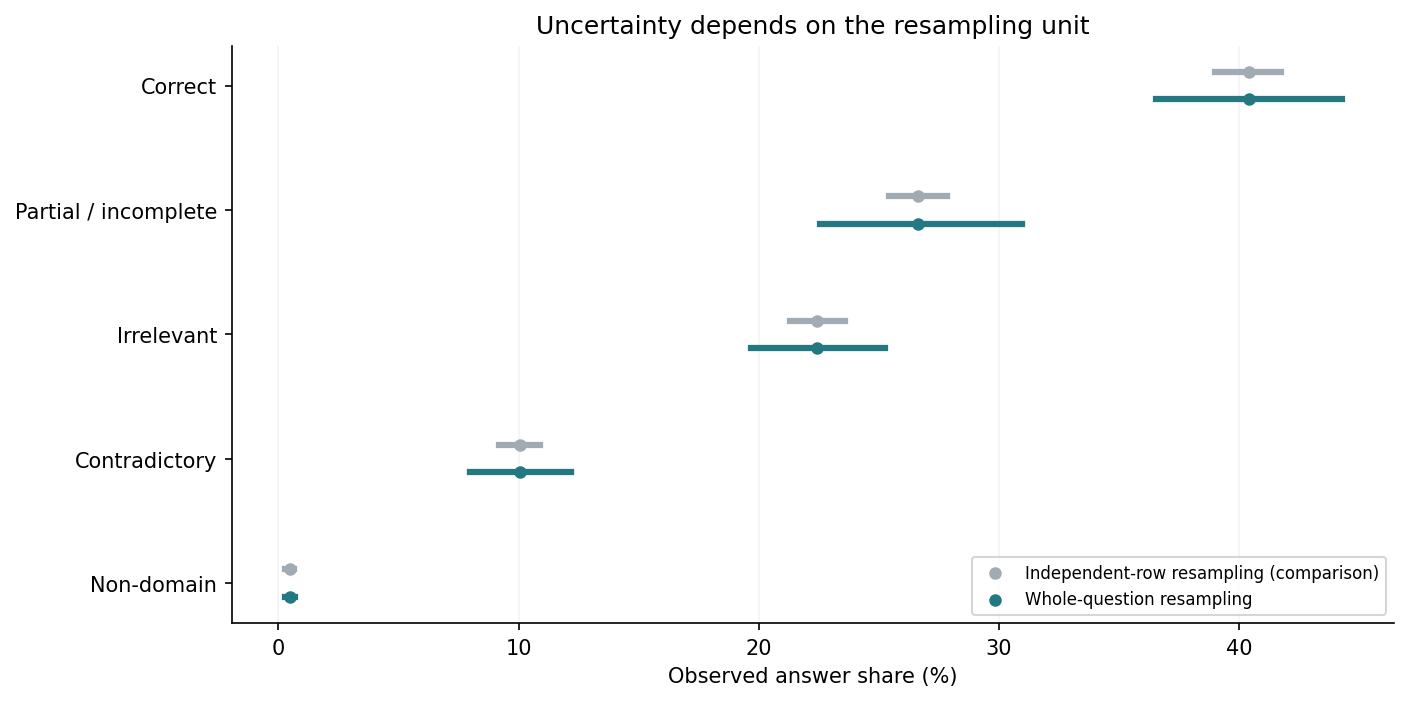

In [3]:
image_path = ROOT / "reports/advanced/figures/01_cluster_resampling.png"
display({"image/png": base64.b64encode(image_path.read_bytes()).decode("ascii")}, raw=True)

## Domain composition and uncertainty

Each domain is resampled by its own questions. Intervals are hidden for domains with fewer than five questions. The observed correct share describes annotations; it is not an intrinsic difficulty or ability estimate.

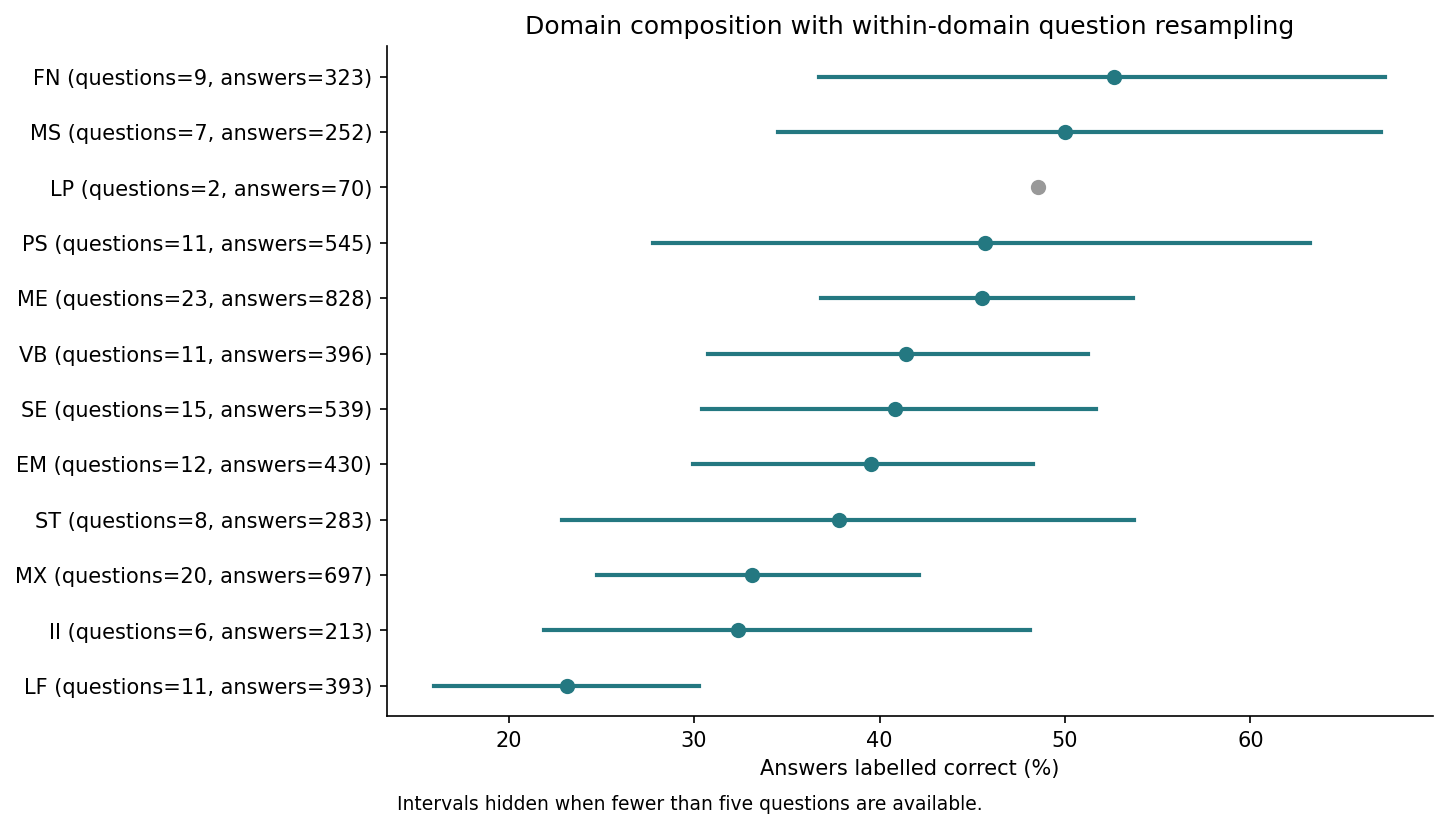

In [4]:
image_path = ROOT / "reports/advanced/figures/02_domain_uncertainty.png"
display({"image/png": base64.b64encode(image_path.read_bytes()).decode("ascii")}, raw=True)

## Three aggregation targets

Pooling answers, averaging question-level shares, and averaging domain-level shares define three different estimands. These are explicit weighting choices, not interchangeable estimates.

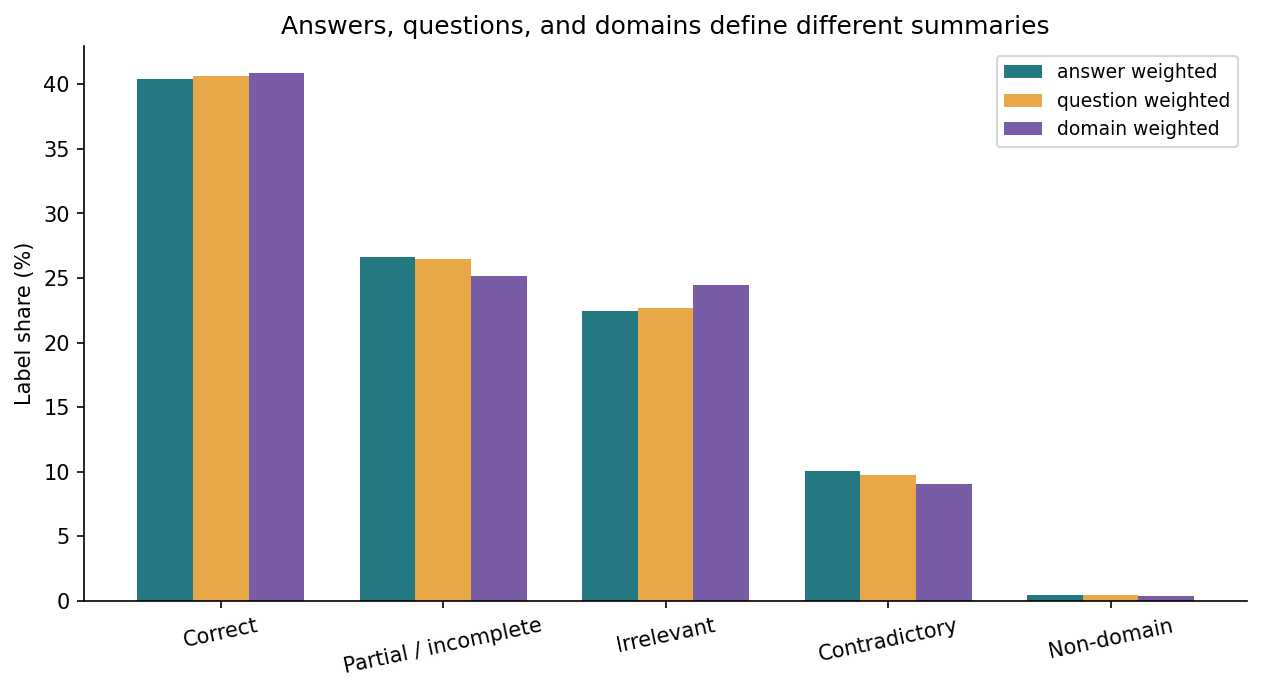

In [5]:
image_path = ROOT / "reports/advanced/figures/03_aggregation_levels.png"
display({"image/png": base64.b64encode(image_path.read_bytes()).decode("ascii")}, raw=True)

## Short-answer slice

The cutoff of at most five whitespace-separated words is exploratory. Within each label, contributing questions are resampled. Small class supports remain a limitation. Length is not a correctness rule.

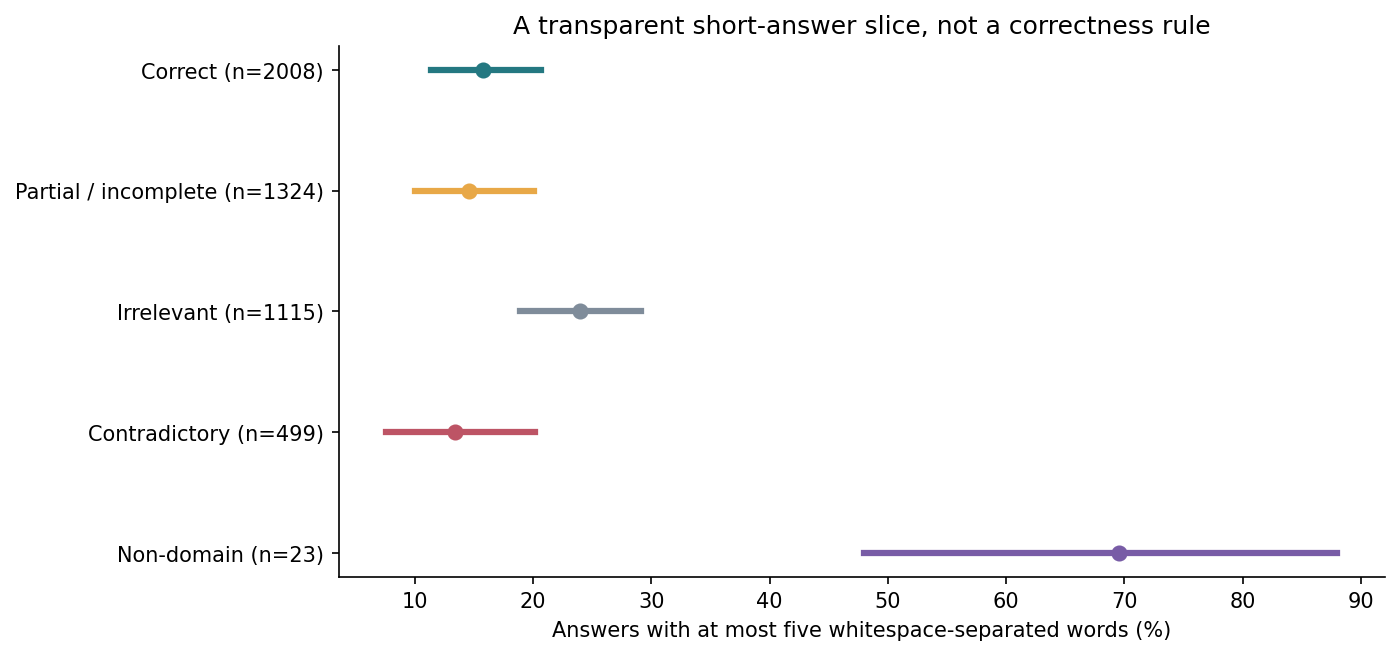

In [6]:
image_path = ROOT / "reports/advanced/figures/04_short_answer_slices.png"
display({"image/png": base64.b64encode(image_path.read_bytes()).decode("ascii")}, raw=True)

## Question versus reference overlap

Word-set Jaccard overlap is calculated separately against question wording and reference wording. Points are descriptive observations, not a fitted classifier or a causal relationship.

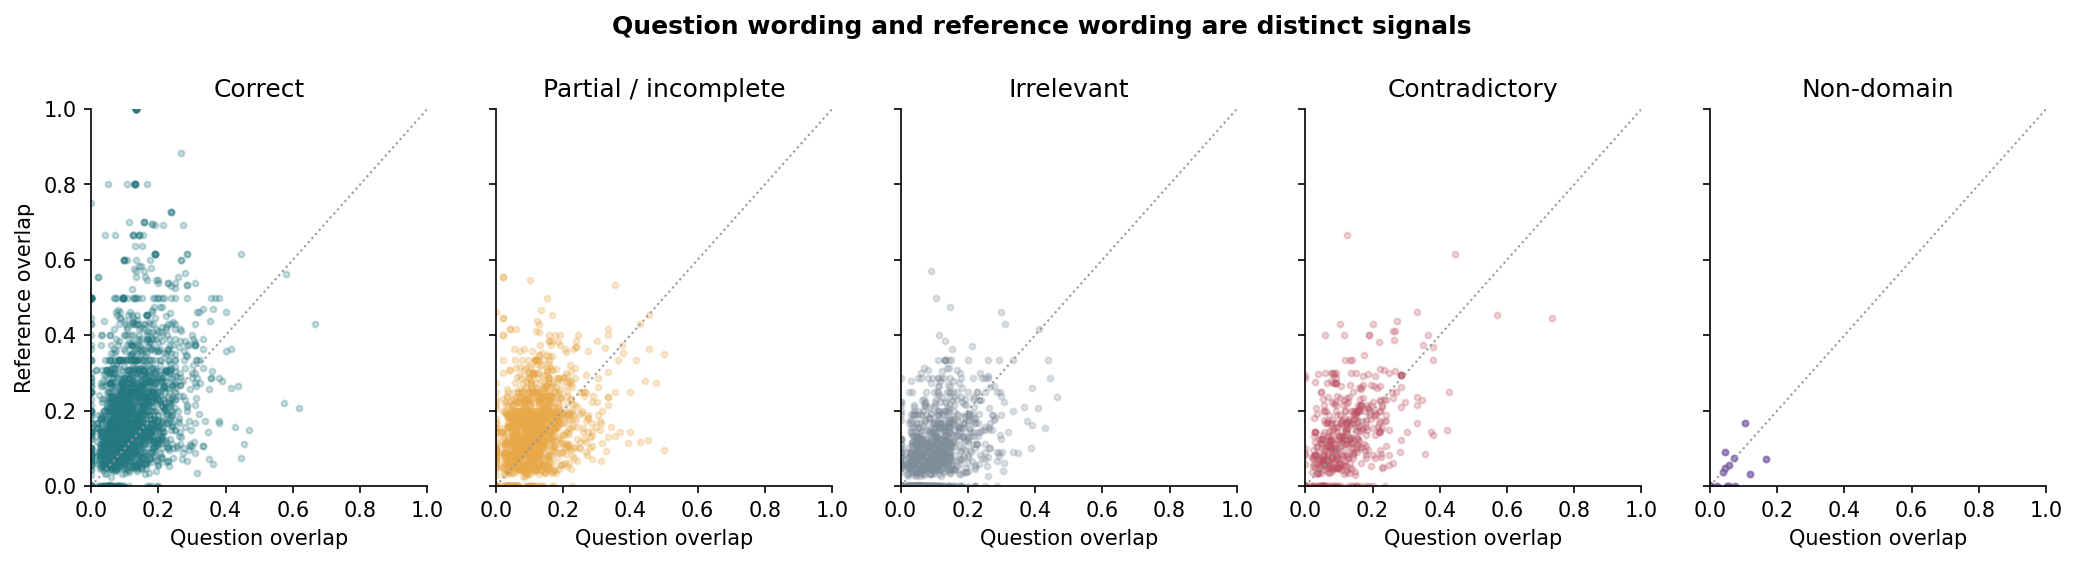

In [7]:
image_path = ROOT / "reports/advanced/figures/05_question_reference_overlap.png"
display({"image/png": base64.b64encode(image_path.read_bytes()).decode("ascii")}, raw=True)

## Feature engineering and redundancy

Spearman correlations summarize monotone associations among numeric features; class labels are not encoded as an ordinal numeric variable. Character count and word count are mechanically related. No independence-based p-values are reported.

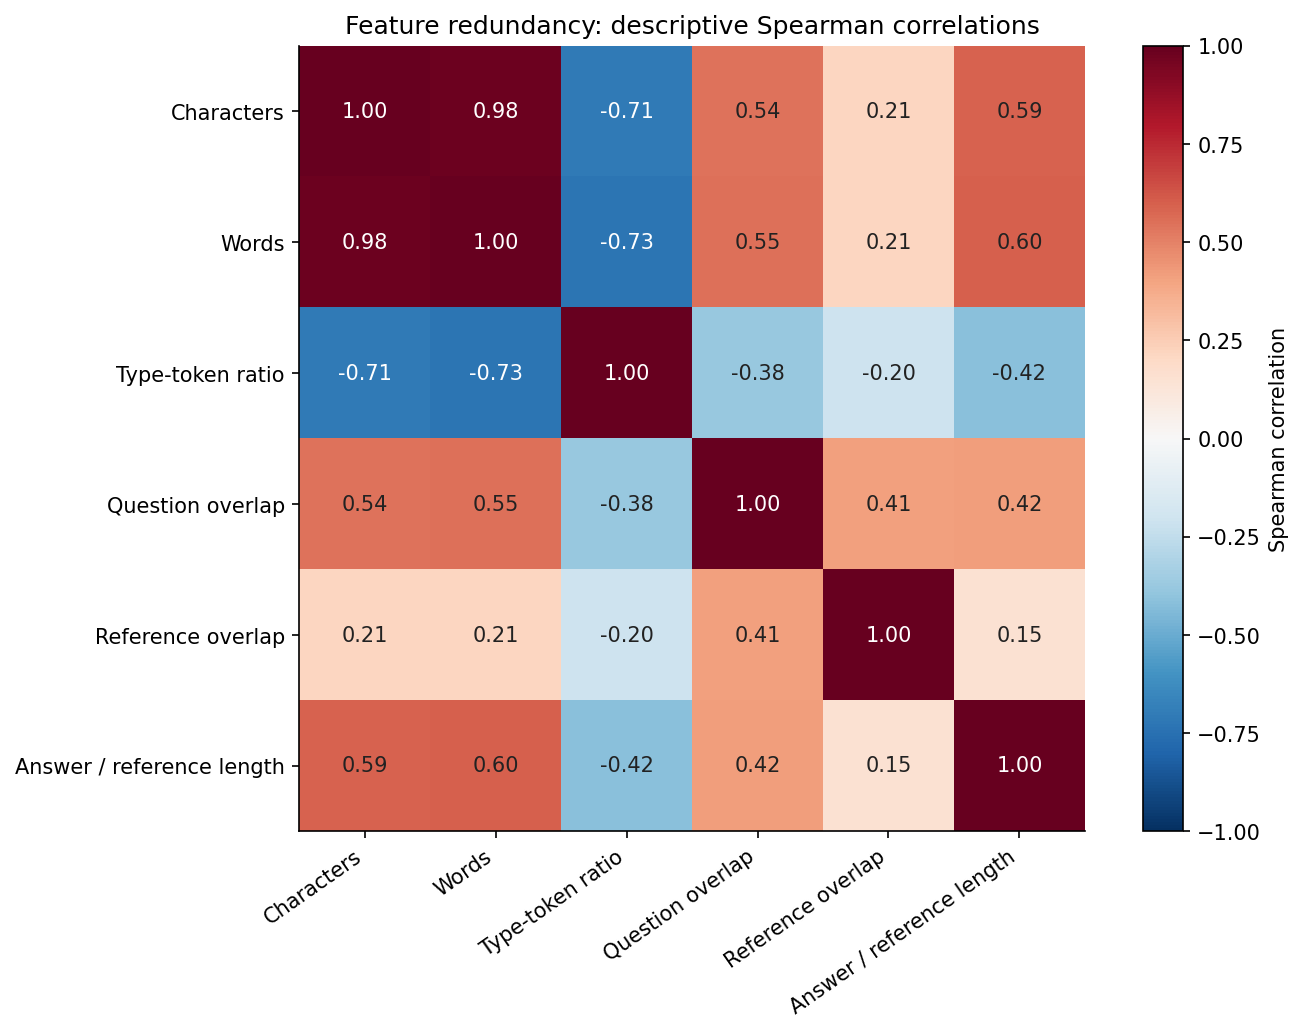

In [8]:
image_path = ROOT / "reports/advanced/figures/06_feature_redundancy.png"
display({"image/png": base64.b64encode(image_path.read_bytes()).decode("ascii")}, raw=True)

## Fit-to-development vocabulary novelty

Build the vocabulary from fit answers only. Count development token occurrences absent from that vocabulary. The calibration partition and official test sets are excluded from this vocabulary analysis.

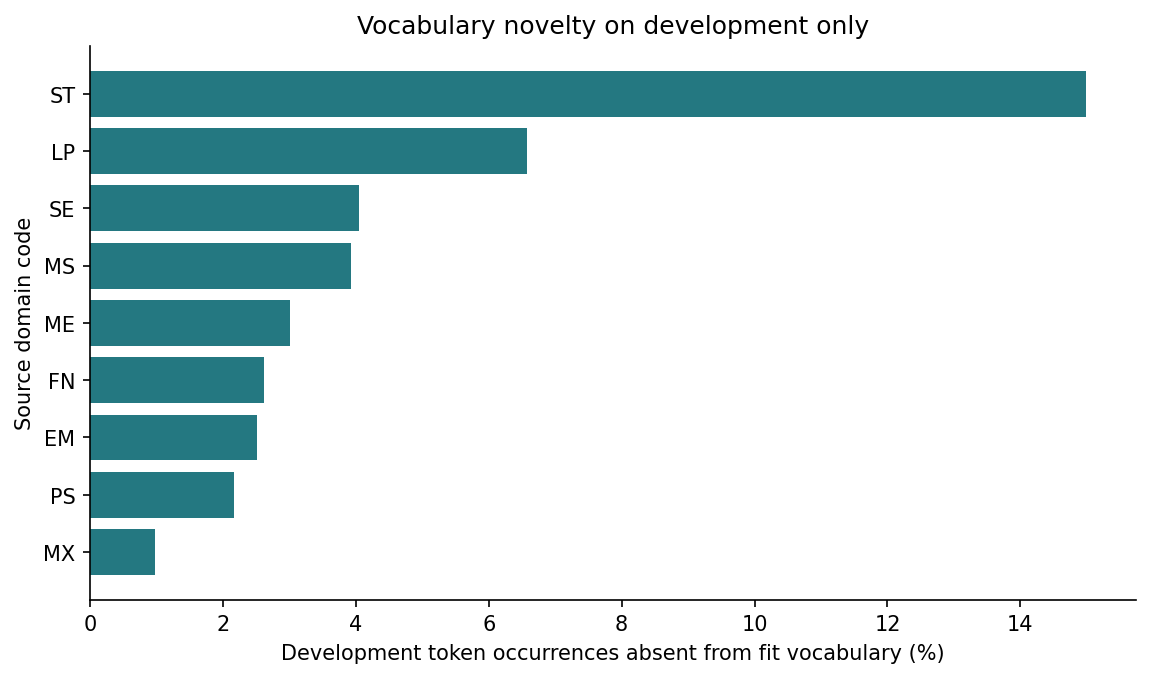

In [9]:
image_path = ROOT / "reports/advanced/figures/07_development_vocabulary_novelty.png"
display({"image/png": base64.b64encode(image_path.read_bytes()).decode("ascii")}, raw=True)

## Exact-input annotation ambiguity

Exactly identical raw question/reference/answer triples can have competing labels. The sum of group size minus the largest label count is an empirical minimum number of training-label disagreements for a deterministic classifier restricted to these raw inputs. It is not population Bayes error or a bound on test accuracy.

In [10]:
print(json.dumps(manifest["raw_input_ambiguity"], indent=2))
print(pd.read_csv(ROOT / "reports/advanced/tables/label_share_resampling.csv").to_string(index=False))

{
  "raw_input_groups": 4827,
  "conflicting_raw_input_groups": 6,
  "minimum_training_label_disagreements": 6,
  "training_records": 4969,
  "minimum_training_disagreement_percentage": 0.12074864157778226,
  "interpretation": "Empirical constraint for deterministic predictions on exactly identical raw question/reference/answer triples; not population Bayes error or test performance."
}
                       label  answer_share  question_cluster_low  question_cluster_high  row_resampling_low  row_resampling_high  answer_support  question_support
                     correct      0.404105              0.365360               0.442740            0.390219             0.417594            2008               135
partially_correct_incomplete      0.266452              0.225683               0.309454            0.254377             0.278532            1324               114
                  irrelevant      0.224391              0.196910               0.252629            0.213121             0

## Limits and follow-up

The training corpus, including its previously audited development/calibration records, is used for descriptive statistics. No calibration/model scores are inspected. The vocabulary novelty diagnostic alone restricts vocabulary construction to fit and evaluation to development. All original split assignments remain unchanged. Resampling does not resolve source selection bias, label uncertainty, or generalization beyond the observed questions and domains. Next: build models using the frozen development protocol, not by selecting thresholds from these exploratory slices.